In [30]:
# tcalibrate.py  (augmented)

import sys
sys.path.append("../")

from typing import Iterable, Optional, List, Tuple, Callable
from qiskit import QuantumCircuit, transpile
from qiskit.circuit.random import random_circuit as qk_random_circuit
from qiskit.circuit import Instruction
import qiskit

from qiskit.quantum_info import Statevector, DensityMatrix
from qiskit_aer import AerSimulator
from qiskit_aer.noise import NoiseModel, depolarizing_error
from qiskit_aer.library import SetDensityMatrix

from pipeline.analysis.postselection import apply_iceberg_postselection
from pipeline.config import PipelineConfig
from simulator.config_presets import ScaledSimulator, StandardSimulator
from translator.core import TranslationContext, TranslationResult
from translator.gate_handlers import translate_and_apply
from simulator.simulator import Simulator

# ---------- Minimal reusable segment translator ----------
def translate_segment(
    program_circuit: QuantumCircuit,
    permutation: List[Tuple[int, int]],
    *,
    fault_tolerant: bool = False,
    verbose: bool = False,
    prelude: Optional[Callable[[TranslationContext], None]] = None,
    postlude: Optional[Callable[[TranslationContext], None]] = None,
    encode_override: bool = False,
) -> QuantumCircuit:
    ctx = TranslationContext.from_config(
        permutation, program_circuit, fault_tolerant=fault_tolerant, verbose=verbose, encode_override=encode_override
    )
    if prelude:
        prelude(ctx)

    ops = list(program_circuit.data)
    skip_next = False
    for i, ci in enumerate(ops):
        if skip_next:
            skip_next = False
            continue
        nxt = ops[i + 1] if i + 1 < len(ops) else None
        consumed = translate_and_apply(ctx, ci, next_op=nxt)
        if consumed is not None:
            if consumed:
                skip_next = True
            else:
                raise RuntimeError("translate_segment: gate application failed")

    if postlude:
        postlude(ctx)

    return ctx.iceberg_set.circuit


# ---- Small logical char-circuits (one op) ----
def make_logical_char_prog(gate: str, targets: Iterable[int], theta: Optional[float] = None) -> QuantumCircuit:
    t = list(targets)
    n_logical = max(t) + 1 if t else 1
    prog = QuantumCircuit(n_logical)
    G = gate.upper()
    if G == "X":
        prog.x(t[0])
    elif G == "Z":
        prog.z(t[0])
    elif G == "RZ":
        if theta is None:
            raise ValueError("theta required for RZ")
        prog.rz(theta, t[0])
    elif G == "CX":
        if len(t) != 2: raise ValueError("CX needs [c,t]")
        prog.cx(t[0], t[1])
    elif G == "CZ":
        if len(t) != 2: raise ValueError("CZ needs [q0,q1]")
        prog.cz(t[0], t[1])
    elif G == "H":
        prog.h(t[0])
    else:
        raise NotImplementedError(gate)
    return prog


def build_full_composed_char_circuit(
    *,
    permutation: List[Tuple[int,int]],
    rand_depth: int = 20,
    rand_seed: Optional[int] = None,
    gate: str = "X",
    targets: Iterable[int] = (0,),
    theta: Optional[float] = None,
    char_label: str = "TEST_SEG",
    fault_tolerant: bool = False,
    verbose: bool = False,
) -> Tuple[QuantumCircuit, QuantumCircuit, QuantumCircuit, QuantumCircuit]:
    # A) ENCODE + random logical program (encoded)
    rand_prog_raw = qk_random_circuit(
        2, depth=rand_depth, seed=rand_seed, measure=False, num_operand_distribution={1: 0.5, 2: 0.5}
    )
    target_basis = ['x', 'z', 'h', 'rz', 'cx', 'cz', 'measure']
    rand_prog = qiskit.transpile(
        rand_prog_raw,
        basis_gates=target_basis,
        optimization_level=2,
    )
    segA = translate_segment(
        rand_prog, permutation,
        fault_tolerant=fault_tolerant, verbose=verbose,
        prelude=lambda ctx: ctx.iceberg_set.encode()
    )
    segA.barrier()

    # B) CHAR logical op → encoded segment (run NOISILY)
    char_prog = make_logical_char_prog(gate, targets, theta)
    segB = translate_segment(
        char_prog, permutation, 
        fault_tolerant=fault_tolerant, verbose=verbose, 
        encode_override=True
    )

    # C) DECODE + MEASURE (ideal)
    empty = QuantumCircuit(char_prog.num_qubits)
    segC = translate_segment(
        empty, permutation,
        fault_tolerant=fault_tolerant, verbose=verbose,
        postlude=lambda ctx: (ctx.iceberg_set.decode(), ctx.iceberg_set.measure()),
        encode_override=True
    )
    return segA, segB, segC, rand_prog_raw


def run_one(permutation: List[Tuple[int,int]], gate: str = "X", targets: Iterable[int] = (0,), theta: Optional[float] = 0.0):
    segA, segB, segC, raw_qc = build_full_composed_char_circuit(
        permutation=permutation,
        rand_depth=10,
        gate=gate, targets=targets,
        char_label="TEST_SEG",
        theta=theta,
    )

    # Preserve register names in the circuit we store in TranslationResult
    tr_circ = QuantumCircuit(*segA.qregs, *segA.cregs)
    tr_circ.compose(segA, inplace=True)
    tr_circ.compose(segB, inplace=True)
    tr_circ.compose(segC, inplace=True)

    tr = TranslationResult(
        circuit=tr_circ,
        permutation=permutation,
        context=TranslationContext.from_config(
            permutation, raw_qc, fault_tolerant=False, verbose=False
        ),
        contains_faults=False,
        fault_tolerant=False,
        fault_log=None,
        verbose=False,
    )

    # ----------------------
    # 1) PRE (ideal): run segA ideally to obtain psiA
    # ----------------------
    nq = segA.num_qubits
    if len(segA) == 0:
        psiA = Statevector.from_label('0' * nq)
    else:
        psiA = Statevector.from_instruction(segA)

    # ----------------------
    # 2) MIDDLE (noisy): run segB with noise, starting from psiA
    # ----------------------
    noise = NoiseModel()
    noise.add_all_qubit_quantum_error(depolarizing_error(0.01, 1), ['x', 'z', 'h', 'rz'])
    noise.add_all_qubit_quantum_error(depolarizing_error(0.02, 2), ['cx', 'cz'])

    sim_mid = AerSimulator(method="density_matrix", noise_model=noise)
    segB_t = transpile(segB, sim_mid, optimization_level=0, layout_method="trivial")
    segB_t.save_density_matrix(label='rho_mid')

    res_mid = sim_mid.run(segB_t, initial_statevector=psiA).result()
    rhoB = res_mid.data(0)['rho_mid']

    # ----------------------
    # 3) POST (ideal): initialize from rhoB and execute segC ideally
    #    IMPORTANT: build the wrapper on segC's EXISTING registers to keep names.
    # ----------------------
    sim_post = AerSimulator(method="density_matrix")

    post_init = QuantumCircuit(*segC.qregs, *segC.cregs)  # re-use same qregs/cregs (names preserved)
    dm = DensityMatrix(rhoB)
    post_init.append(SetDensityMatrix(dm), post_init.qubits)
    post_init.compose(segC, inplace=True)

    post_t = transpile(post_init, sim_post, optimization_level=0, layout_method="trivial")
    res_post = sim_post.run(post_t).result()

    # Final execution through your Simulator to keep downstream identical.
    sim_config = StandardSimulator(repetitions=500_000)
    simulator = Simulator(sim_config)
    sim_res_raw = simulator.run(circuit=post_t)

    sim_results = apply_iceberg_postselection([tr], [sim_res_raw])
    return sim_results

from typing import Iterable, List, Optional, Tuple, Dict, Any
import numpy as np
import math
from concurrent.futures import ThreadPoolExecutor, as_completed
import matplotlib.pyplot as plt

def run_many(
    permutation: List[Tuple[int,int]],
    gate: str = "X",
    targets: Iterable[int] = (0,),
    theta: Optional[float] = 0.0,
    m: int = 100,
    seeds: Optional[Iterable[int]] = None,
    parallel: bool = False,
    max_workers: Optional[int] = None,
) -> Dict[str, Any]:
    """
    Run `run_one` multiple times to build metric distributions.

    Parameters
    ----------
    permutation : List[Tuple[int,int]]
        Logical->patch mapping used inside `build_full_composed_char_circuit`.
    gate : str
        Characterization gate to apply in segB (e.g., "X", "Z", "H", "RZ").
    targets : Iterable[int]
        Logical target indices for the gate in segB.
    theta : float | None
        Angle for parametric gates (e.g., RZ). Ignored for non-parametric gates.
    m : int
        Number of repetitions.
    seeds : Iterable[int] | None
        Optional per-run seeds for any internal randomness your pipeline might use.
        If provided and has length m, each iteration sets `np.random.seed(seeds[i])`
        before calling `run_one`. If None, no explicit seeding is done.
    parallel : bool
        If True, uses a thread pool to run iterations concurrently.
        (Good if `run_one` releases the GIL and/or calls out to native code.)
    max_workers : int | None
        Max workers for the thread pool. Defaults to `min(32, os.cpu_count() or 1)`.

    Returns
    -------
    Dict[str, Any]
        {
          'permutation': List[Tuple[int,int]],
          'gate': str,
          'targets': Tuple[int, ...],
          'theta': float | None,
          'm': int,
          'tvd': np.ndarray,                 # shape (m,)
          'selection_rate': np.ndarray,      # shape (m,)
          'summary': {
              'tvd_mean': float, 'tvd_std': float,
              'sel_mean': float, 'sel_std': float,
              'tvd_p10': float, 'tvd_p50': float, 'tvd_p90': float,
              'sel_p10': float, 'sel_p50': float, 'sel_p90': float,
          }
        }
    """
    # Prepare optional seeds
    use_seeds = list(seeds) if seeds is not None else None
    if use_seeds is not None and len(use_seeds) != m:
        raise ValueError(f"`seeds` length ({len(use_seeds)}) must equal m ({m}).")

    # Storage
    tvd_vals = np.empty(m, dtype=float)
    sel_vals = np.empty(m, dtype=float)

    def _job(i: int):
        if use_seeds is not None:
            np.random.seed(use_seeds[i])
        # Call the provided run_one exactly as-is
        sim_results = run_one(permutation=permutation, gate=gate, targets=targets, theta=theta)
        # Expect a list-like with one TranslationResult aggregate
        sr0 = sim_results[0]
        tvd = getattr(sr0, "logical_total_variation_distance", None)
        sel = getattr(sr0, "logical_selection_rate", None)
        if tvd is None or sel is None:
            raise AttributeError(
                "Expected `logical_total_variation_distance` and `logical_selection_rate` on sim_results[0]."
            )
        return i, float(tvd), float(sel)

    if parallel:
        with ThreadPoolExecutor(max_workers=max_workers) as ex:
            futures = [ex.submit(_job, i) for i in range(m)]
            for fut in as_completed(futures):
                i, tvd, sel = fut.result()
                tvd_vals[i] = tvd
                sel_vals[i] = sel
    else:
        for i in range(m):
            _, tvd, sel = _job(i)
            tvd_vals[i] = tvd
            sel_vals[i] = sel

    # Summaries
    def _pct(a: np.ndarray, p: float) -> float:
        return float(np.percentile(a, p))

    summary = {
        "tvd_mean": float(np.mean(tvd_vals)),
        "tvd_std": float(np.std(tvd_vals, ddof=1)) if m > 1 else 0.0,
        "sel_mean": float(np.mean(sel_vals)),
        "sel_std": float(np.std(sel_vals, ddof=1)) if m > 1 else 0.0,
        "tvd_p10": _pct(tvd_vals, 10),
        "tvd_p50": _pct(tvd_vals, 50),
        "tvd_p90": _pct(tvd_vals, 90),
        "sel_p10": _pct(sel_vals, 10),
        "sel_p50": _pct(sel_vals, 50),
        "sel_p90": _pct(sel_vals, 90),
    }

    return {
        "permutation": permutation,
        "gate": gate,
        "targets": tuple(targets),
        "theta": theta,
        "m": m,
        "tvd": tvd_vals,
        "selection_rate": sel_vals,
        "summary": summary,
    }


def plot_run_many_distributions(
    results: Dict[str, Any],
    bins: int = 30,
    figsize: Tuple[float, float] = (11, 4.5),
    show_means: bool = True,
    tight: bool = True,
):
    """
    Plot histograms for `logical_total_variation_distance` and `logical_selection_rate`
    from the dict returned by `run_many`.

    Parameters
    ----------
    results : dict
        Output of `run_many`.
    bins : int
        Number of histogram bins.
    figsize : (w, h)
        Figure size in inches.
    show_means : bool
        If True, draw a vertical line at the mean of each distribution.
    tight : bool
        If True, call plt.tight_layout() before showing.
    """
    tvd = np.asarray(results["tvd"], dtype=float)
    sel = np.asarray(results["selection_rate"], dtype=float)
    tvd_mean = float(np.mean(tvd))
    sel_mean = float(np.mean(sel))

    fig, axes = plt.subplots(1, 2, figsize=figsize)

    ax0 = axes[0]
    ax0.hist(tvd, bins=bins)
    ax0.set_title("Logical TVD Distribution")
    ax0.set_xlabel("logical_total_variation_distance")
    ax0.set_ylabel("Count")
    if show_means:
        ax0.axvline(tvd_mean, linestyle="--")
        ax0.text(tvd_mean, ax0.get_ylim()[1]*0.95, f"mean={tvd_mean:.4f}", rotation=90, va='top', ha='right')

    ax1 = axes[1]
    ax1.hist(sel, bins=bins)
    ax1.set_title("Logical Selection Rate Distribution")
    ax1.set_xlabel("logical_selection_rate")
    ax1.set_ylabel("Count")
    if show_means:
        ax1.axvline(sel_mean, linestyle="--")
        ax1.text(sel_mean, ax1.get_ylim()[1]*0.95, f"mean={sel_mean:.4f}", rotation=90, va='top', ha='right')

    if tight:
        plt.tight_layout()
    plt.show()

In [ ]:
x_run =     run_one([(0,0), (0,1)], gate="X")
z_run =     run_one([(0,0), (0,1)], gate="Z")
h_s_run =   run_one([(0,0), (0,1)], gate="H")
h_p_run =   run_one([(0,0), (1,0)], gate="H")
rz_run =    run_one([(0,0), (0,1)], gate="RZ", theta=1)
cx_i_run =  run_one([(0,0), (0,1)], gate="CX", targets=(0,1))
cx_t_run =  run_one([(0,0), (1,0)], gate="CX", targets=(0,1))

X (grouped) summary: {'tvd_mean': 0.009794840113719748, 'tvd_std': 0.00022300120807648293, 'sel_mean': 0.4291497, 'sel_std': 0.0006994306011529255, 'tvd_p10': 0.009503773518338289, 'tvd_p50': 0.00978529449839318, 'tvd_p90': 0.010075647334699716, 'sel_p10': 0.428203, 'sel_p50': 0.429227, 'sel_p90': 0.430007}


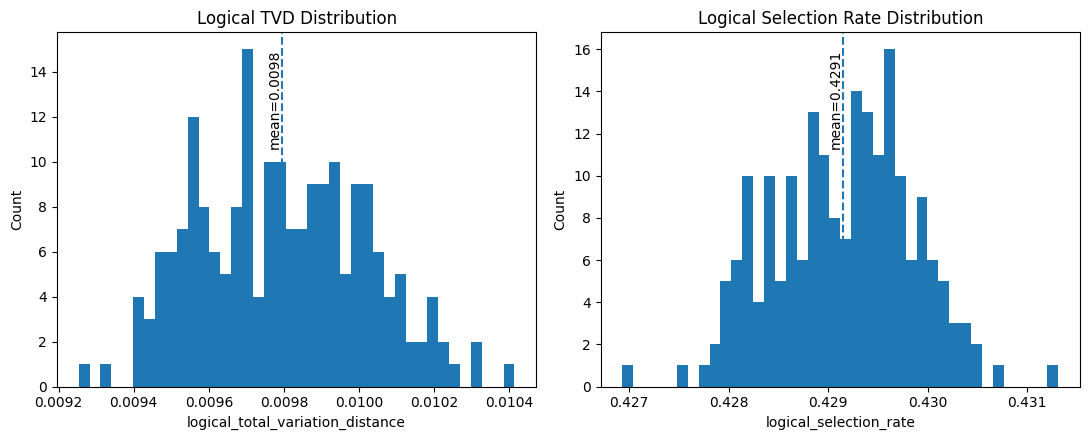

In [31]:
# X (grouped: [(0,0), (0,1)])
x_results = run_many(
    permutation=[(0,0), (0,1)],
    gate="X",
    targets=(0,),
    theta=0.0,
    m=200,
    parallel=True,
    max_workers=None,
)
print("X (grouped) summary:", x_results["summary"])
plot_run_many_distributions(x_results, bins=40)


Z (grouped) summary: {'tvd_mean': 0.00924724342990997, 'tvd_std': 0.00021034968386523937, 'sel_mean': 0.43259185, 'sel_std': 0.0006896852661407666, 'tvd_p10': 0.008997150855761213, 'tvd_p50': 0.009244083862176766, 'tvd_p90': 0.009519787094490242, 'sel_p10': 0.4316644, 'sel_p50': 0.432596, 'sel_p90': 0.4335066}


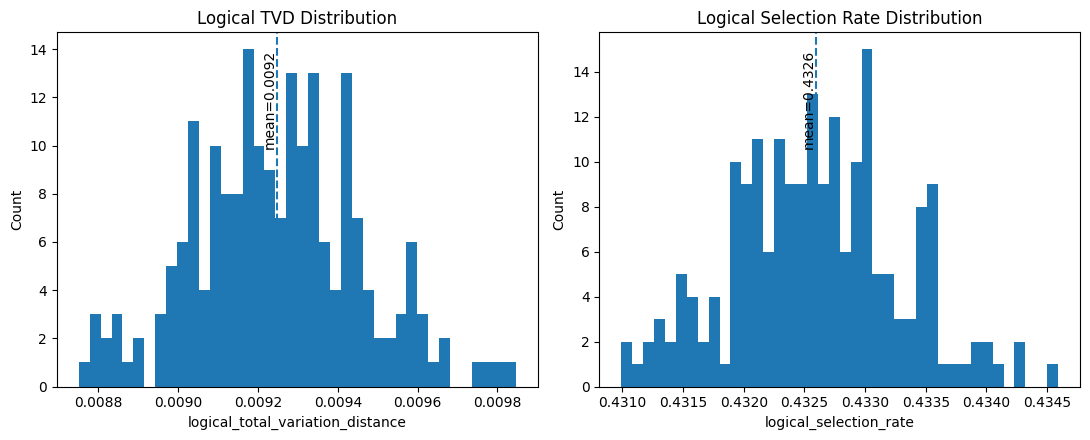

In [35]:
# Z (grouped: [(0,0), (0,1)])
z_results = run_many(
    permutation=[(0,0), (0,1)],
    gate="Z",
    targets=(0,),
    theta=0.0,
    m=200,
    parallel=True,
    max_workers=None,
)
print("Z (grouped) summary:", z_results["summary"])
plot_run_many_distributions(z_results, bins=40)

H same-patch (grouped) summary: {'tvd_mean': 0.004467496292794493, 'tvd_std': 0.0010637234357290554, 'sel_mean': 0.40490946, 'sel_std': 0.0007201178772853297, 'tvd_p10': 0.0034454194578230637, 'tvd_p50': 0.004192434360521958, 'tvd_p90': 0.00594767961094356, 'sel_p10': 0.4038886, 'sel_p50': 0.40495000000000003, 'sel_p90': 0.40582339999999995}


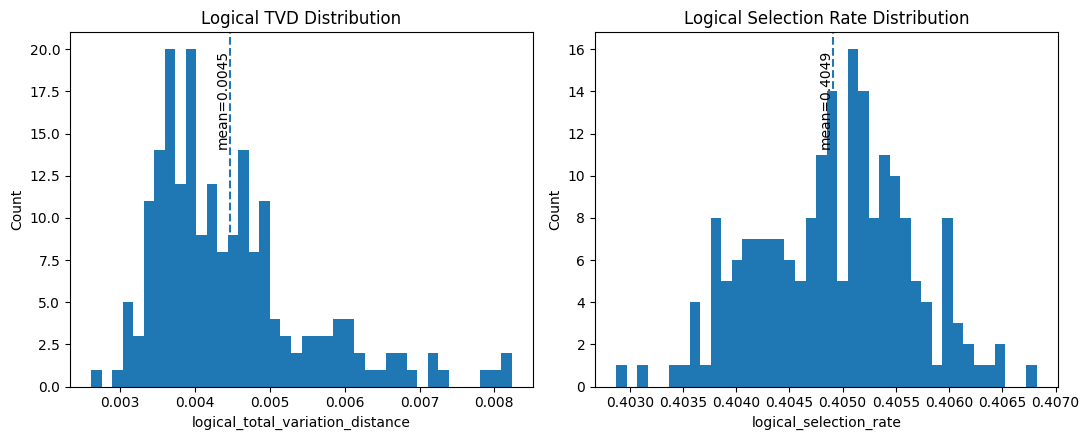

In [36]:
# H same-patch (grouped: [(0,0), (0,1)])
h_s_results = run_many(
    permutation=[(0,0), (0,1)],
    gate="H",
    targets=(0,),
    theta=0.0,
    m=200,
    parallel=True,
    max_workers=None,
)
print("H same-patch (grouped) summary:", h_s_results["summary"])
plot_run_many_distributions(h_s_results, bins=40)

H cross-patch summary: {'tvd_mean': 0.009682256471968792, 'tvd_std': 0.0008524277709075652, 'sel_mean': 0.17411289, 'sel_std': 0.0005454489901947971, 'tvd_p10': 0.008929055095371551, 'tvd_p50': 0.009419702683531053, 'tvd_p90': 0.01081233184420596, 'sel_p10': 0.17333360000000003, 'sel_p50': 0.174112, 'sel_p90': 0.1747842}


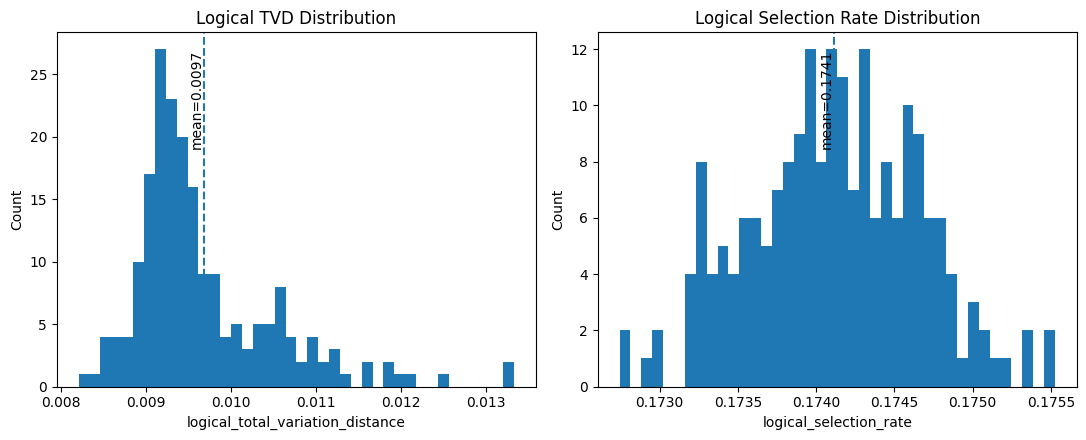

In [37]:
# HH layout (permutation: [(0,0), (1,0)])
h_p_results = run_many(
    permutation=[(0,0), (1,0)],
    gate="H",
    targets=(0,),
    theta=0.0,
    m=200,
    parallel=True,
    max_workers=None,
)
print("H cross-patch summary:", h_p_results["summary"])
plot_run_many_distributions(h_p_results, bins=40)

In [ ]:
# RZ(theta=1) (grouped: [(0,0), (0,1)])
rz_results = run_many(
    permutation=[(0,0), (0,1)],
    gate="RZ",
    targets=(0,),
    theta=1.0,
    m=200,
    parallel=True,
    max_workers=None,
)
print("RZ(theta=1) summary:", rz_results["summary"])
plot_run_many_distributions(rz_results, bins=40)

CX intra-patch summary: {'tvd_mean': 0.009023050984214364, 'tvd_std': 0.00020051824912353583, 'sel_mean': 0.420452, 'sel_std': 0.00047234732983261513, 'tvd_p10': 0.008909620733248838, 'tvd_p50': 0.009023050984214364, 'tvd_p90': 0.009136481235179888, 'sel_p10': 0.42018479999999997, 'sel_p50': 0.420452, 'sel_p90': 0.4207192}


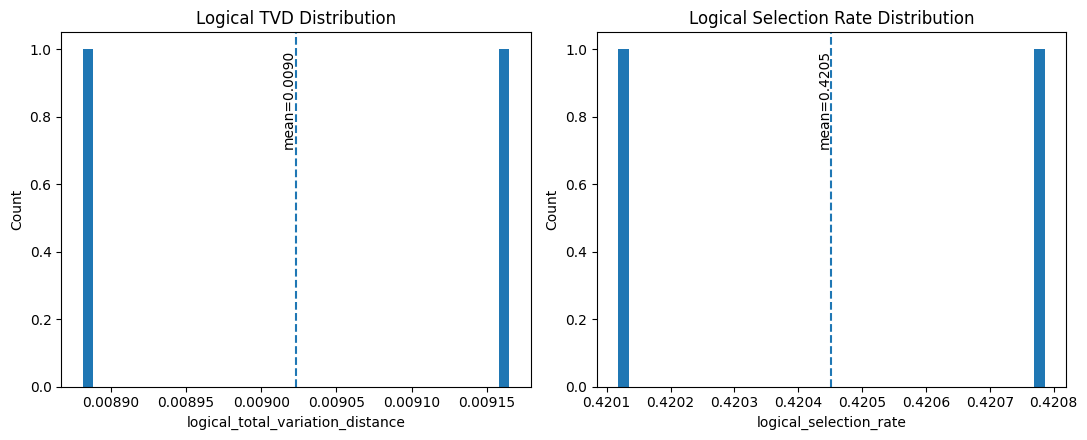

In [ ]:
# CX intra-patch (grouped permutation, targets=(0,1))
cx_i_results = run_many(
    permutation=[(0,0), (0,1)],
    gate="CX",
    targets=(0,1),
    theta=0.0,
    m=200,
    parallel=True,
    max_workers=None,
)
print("CX intra-patch summary:", cx_i_results["summary"])
plot_run_many_distributions(cx_i_results, bins=40)

In [ ]:
# CX transversal (cross-patch permutation, targets=(0,1))
cx_t_results = run_many(
    permutation=[(0,0), (1,0)],
    gate="CX",
    targets=(0,1),
    theta=0.0,
    m=200,
    parallel=True,
    max_workers=None,
)
print("CX transversal summary:", cx_t_results["summary"])
plot_run_many_distributions(cx_t_results, bins=40)